# Postprocessing

In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import h5py
import numpy as np
import pandas as pd
from matplotlib.patches import Circle
import os
import myfunctions
import h5py
import TM26_unet as unet


GPU = True
MULTIGPU = True

DELETE_OLD_FILES = False
DELETE_OLD_FILES = False

SMALL_SIZE = 18
MEDIUM_SIZE = 22
BIGGER_SIZE = 24
GPU = True

diffLimDir = "dataInputs/"
testDataDir = "output_prep/"
outputDir = "output_post/"
inputDir = "output_infer/"

datasets_name = ["lightfield", "WFSxy", "WFSxy_DM", "WFSxy_DM_intensity", "WFSxy_intensity"]
dataset_name_readable = ["lightfield", "WFSxy", "WFSxy and DM commands", "WFSxy, SHWFS intensity map and DM commands", "WFSxy and SHWFS intensity map"]

batch_size = 64

dataset_numbers = len(datasets_name)



SMALL_SIZE = 18
MEDIUM_SIZE = 22
BIGGER_SIZE = 24
GPU = True



In [2]:
# for dataset_number in range(dataset_numbers):
dataset_number = 1

## load data

In [ ]:
# with h5py.File(inputDir+datasets_name[dataset_number]+"/predictions.h5", 'r') as temp:
#     inference = temp[list(temp.keys())[0]][()]
# truth = []
# with h5py.File(testDataDir+"ao_ipsf_test_1.h5", 'r') as temp:
#     key = list(temp.keys())
#     tempdata = temp[key[0]][()][:]
#     for i in range(tempdata.shape[0]):
#         truth.append(myfunctions.pixel_adder(tempdata[i],final_shape=[270, 270]))

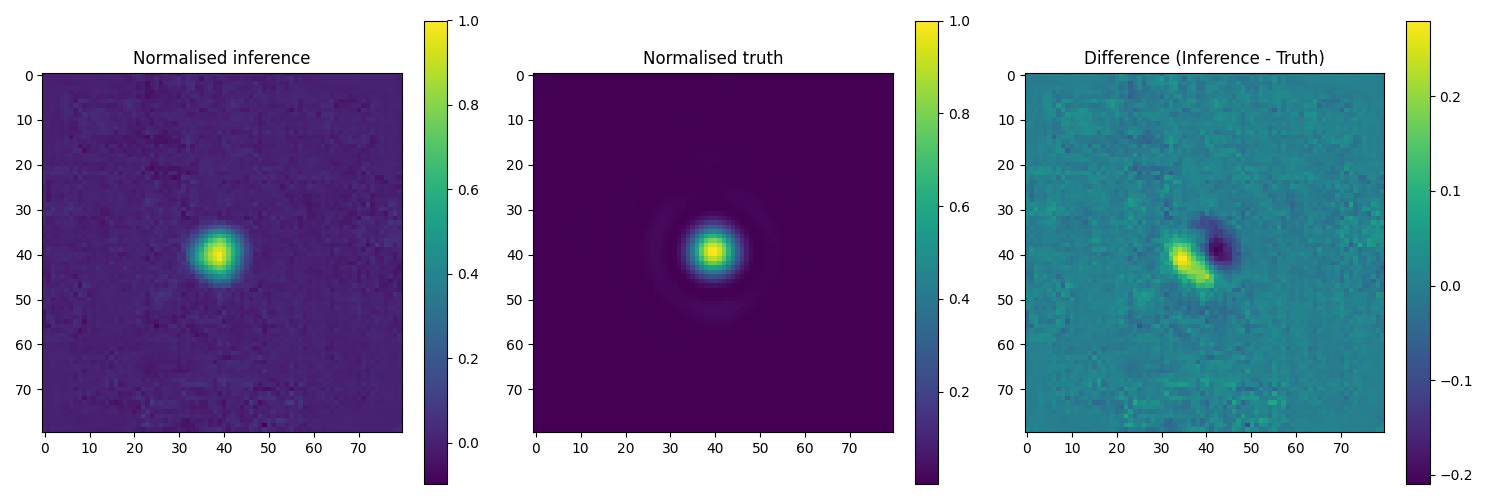

In [44]:
with h5py.File(inputDir+datasets_name[dataset_number]+"/predictions.h5", 'r') as temp:
    inference = temp[list(temp.keys())[0]][()]
    
with h5py.File(testDataDir+"ao_ipsf_test_1.h5", 'r') as temp:
    key = list(temp.keys())
    truth = temp[key[0]][()][:]

plt.close('all')
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

im0 = axes[0].imshow(inference[10]/np.max(inference[10]))
axes[0].set_title('Normalised inference')
fig.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(truth[10]/np.max(truth[10]))
axes[1].set_title('Normalised truth')
fig.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(inference[10]/np.max(inference[10]) - truth[10]/np.max(truth[10]))
axes[2].set_title('Difference (Inference - Truth)')
fig.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()

## FFT

selon mathft.pro

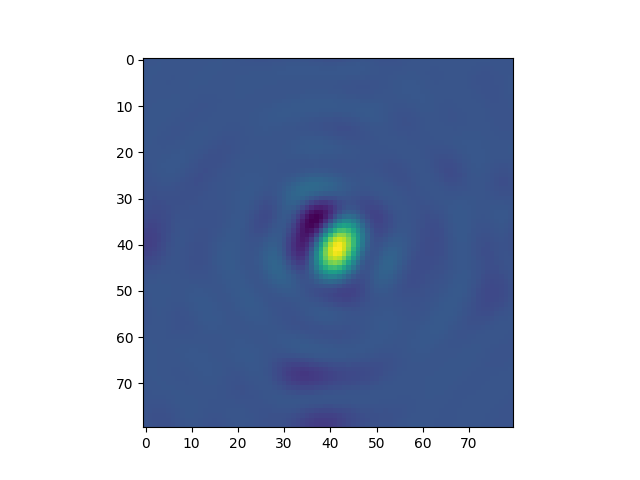

In [78]:
with h5py.File("dataInputs/ipsf_difflim.h5", 'r') as temp:
    ipsf_difflim = temp[list(temp.keys())[0]][()]

ipsf_difflim /= ipsf_difflim.sum()
plt.close(0)
plt.figure(0)
plt.imshow(ipsf_difflim-truth[0]/truth[0].sum())

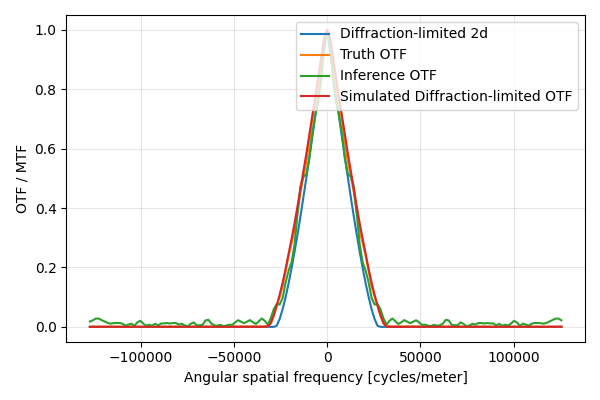

237.3398151888908 315.3347960709523 543.9165769088172
Strehl_inf: 0.9428628711138571
Strehl_truth: 0.9572964564526406


In [165]:
def pad_center(arr, pad):
    n = arr.shape[0]
    N = n * pad
    out = np.zeros((N, N))
    i0 = N // 2 - n // 2
    out[i0:i0+n, i0:i0+n] = arr
    return out

def otf_from_psf(psf):
    psf = psf / psf.sum()
    return np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(psf)))

D = 17.5e-3  # [m]
wl = 632.8e-9  # [m]
pad = 2
dimmat_psf = 80
N = dimmat_psf * pad
dx = 3.928571e-06
fc = D / wl

freq = np.fft.fftshift(np.fft.fftfreq(N, d=dx))
freq_n = np.abs(freq) / fc

padded_truth = pad_center(truth[0], pad)
padded_inf = pad_center(inference[0], pad)
padded_ipsf_difflim = pad_center(ipsf_difflim, pad)

OTF_truth = np.abs(otf_from_psf(padded_truth))
OTF_inf = np.abs(otf_from_psf(padded_inf))
OTF_ipsf_difflim = np.abs(otf_from_psf(padded_ipsf_difflim))

OTF_tel = myfunctions.telescope_otf(np.abs(np.meshgrid(freq_n, freq_n)[0]**2 + np.meshgrid(freq_n, freq_n)[1]**2)**0.5)

plt.figure(figsize=(6, 4))
plt.plot(freq, OTF_tel[N//2, :], label="Diffraction-limited 2d")
plt.plot(freq, OTF_truth[N//2, :], label="Truth OTF")
plt.plot(freq, OTF_inf[N//2, :], label="Inference OTF")
plt.plot(freq, OTF_ipsf_difflim[N//2, :], label="Simulated Diffraction-limited OTF")
plt.xlabel("Angular spatial frequency [cycles/meter]")
plt.ylabel("OTF / MTF")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Strehl_truth = np.sum(OTF_truth[60:100, 60:100]) / np.sum(OTF_ipsf_difflim[60:100, 60:100])
Strehl_inf = np.sum(OTF_inf[60:100, 60:100]) / np.sum(OTF_ipsf_difflim[60:100, 60:100])

print(np.sum(OTF_tel), np.sum(OTF_truth), np.sum(OTF_inf))
print(f"Strehl_inf: {Strehl_inf}")
print(f"Strehl_truth: {Strehl_truth}")

[[1.]]
[[0.]]


## Strehl



In [ ]:

# relative_strehl_dist = (interpolation_strehl - truth_strehl) / truth_strehl

In [ ]:
lower_bound = truth_strehl * 0.9  # -10%
upper_bound = truth_strehl * 1.1  # +10%

plt.close('all')
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [3, 2]})

# Top plot: Strehl ratios
ax.plot(truth_strehl, 'k', label=r'$S_{ref}$')
ax.plot(interpolation_strehl, 'r', label=r'$S_{R}$')
ax.set_ylim([0, 1])
ax.fill_between(range(len(truth_strehl)), lower_bound, upper_bound, 
                color='gray', alpha=0.3, edgecolor='none', label='±10% of expected Strehl ratio')
ax.set_ylabel('Strehl ratio [-]', fontsize=MEDIUM_SIZE)
ax.tick_params(axis='y', labelsize=SMALL_SIZE)
ax.legend(fontsize=SMALL_SIZE)
ax.set_title("Comparison of Strehl ratios for instantaneous PSFs", fontsize=BIGGER_SIZE)
ax.set_xlim([0, inference.shape[0]])
ax.grid()

# Bottom plot: Relative distance (ax2 is now a separate subplot below)
ax2.plot(relative_strehl_dist * 100, 'k', label=r"$\frac{S_{R}-S_{ref}}{S_{ref}}$")
ax2.set_ylabel('Relative distance [%]', fontsize=MEDIUM_SIZE, color='k')
ax2.tick_params(axis='y', labelsize=SMALL_SIZE, colors='k')
symetric_lim = max(abs(np.min(relative_strehl_dist) * 110), abs(np.max(relative_strehl_dist) * 110))
ax2.set_ylim([-symetric_lim, symetric_lim])
ax2.legend(fontsize=MEDIUM_SIZE)
ax2.set_xlabel('Iteration [-]', fontsize=MEDIUM_SIZE)
ax2.set_xlim([0, inference.shape[0]])
ax2.grid()
ax2.tick_params(axis='x', labelsize=SMALL_SIZE)

plt.tight_layout()
plt.show()

In [ ]:
plt.close('all')
plt.figure(figsize=(10, 8))
plt.plot(truth_strehl,interpolation_strehl,'.k')
plt.xlim([0,1])
plt.ylim([0,1])
plt.xlabel('Truth Strehl', fontsize=MEDIUM_SIZE)
plt.ylabel('Interpolation Strehl', fontsize=MEDIUM_SIZE)
plt.xticks(fontsize=SMALL_SIZE)
plt.yticks(fontsize=SMALL_SIZE)
plt.title(r'$S_R(S_{ref})$', fontsize=BIGGER_SIZE)
plt.grid(True)
plt.show()

## Rotational average

1. Find center
2. Average the PSF
3. compare